# Arquitetura

In [102]:
import sys
from pathlib import Path

# permite importar o pacote local sem instalar
REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import torch
from torch import nn
from torch.nn import Module, ModuleList

from denoising_diffusion_pytorch.denoising_diffusion_pytorch import (
    ResnetBlock,
    Downsample,
    Upsample,
    SinusoidalPosEmb,
    Attention,
)

def pick_device():
    # escolhe a GPU com mais memória livre (as GPUs da máquina são compartilhadas)
    if not torch.cuda.is_available():
        return 'cpu'
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    for i, f in enumerate(free):
        print(f'cuda:{i} {torch.cuda.get_device_name(i)}: {f / 2**30:.1f} GB livres')
    return f'cuda:{max(range(len(free)), key = free.__getitem__)}'

device = pick_device()
torch.cuda.set_device(device) if device != 'cpu' else None
device

cuda:0 NVIDIA T1000 8GB: 4.6 GB livres
cuda:1 NVIDIA T1000 8GB: 5.7 GB livres


'cuda:1'

In [103]:
class TimeEmbedding(Module):
    def __init__(self, dim, time_dim):
        super().__init__()
        self.net = nn.Sequential(
            SinusoidalPosEmb(dim),        # Eq. (23)
            nn.Linear(dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

    def forward(self, t):
        return self.net(t)

In [104]:
class CDDPMEncoder(Module):
    def __init__(
        self,
        dim = 64,
        dim_mults = (1, 1, 2, 2, 4),     # 5 ResNet blocks
        channels = 1,                    # x_t (difrações)
        cond_channels = 1,               # y   (full-wavefield)
        num_res_modules = 2,             # residual modules por bloco no encoder
        dropout = 0.,
    ):
        super().__init__()
        self.channels = channels
        self.cond_channels = cond_channels

        # 3×3 Conv de entrada sobre [y ; x_t]
        self.init_conv = nn.Conv2d(channels + cond_channels, dim, 3, padding = 1)

        # time embedding compartilhado por todos os ResNet blocks
        self.time_dim = dim * 4
        self.time_mlp = TimeEmbedding(dim, self.time_dim)

        dims = [dim, *(dim * m for m in dim_mults)]
        self.in_out = list(zip(dims[:-1], dims[1:]))
        num_blocks = len(self.in_out)

        self.skip_dims = [dim]           # canais de cada skip, na ordem em que são empilhadas

        self.downs = ModuleList([])
        for ind, (dim_in, dim_out) in enumerate(self.in_out):
            is_last = ind == num_blocks - 1

            res_modules = ModuleList([
                ResnetBlock(dim_in, dim_in, time_emb_dim = self.time_dim, dropout = dropout)
                for _ in range(num_res_modules)
            ])

            sampler = Downsample(dim_in, dim_out) if not is_last else nn.Conv2d(dim_in, dim_out, 3, padding = 1)

            # Compoe os 5 blocos Resnet blocos do encoder: 2 Residual modules (res_modules) + 1 Down-sampling (sampler)
            self.downs.append(ModuleList([res_modules, sampler]))

            self.skip_dims += [dim_in] * num_res_modules
            if not is_last:
                self.skip_dims.append(dim_out)

        self.out_dim = dims[-1]

    @property
    def downsample_factor(self):
        return 2 ** (len(self.downs) - 1)

    def forward(self, x_t, y, time):
        assert all(d % self.downsample_factor == 0 for d in x_t.shape[-2:]), \
            f'H e W precisam ser divisíveis por {self.downsample_factor}'

        x = torch.cat((y, x_t), dim = 1)    # condicionamento: concatena y com x_t
        x = self.init_conv(x)

        t = self.time_mlp(time)

        skips = [x]                         # skip da 3×3 Conv (usado pelo bloco final do decoder)

        for ind, (res_modules, sampler) in enumerate(self.downs):
            is_last = ind == len(self.downs) - 1

            for res in res_modules:
                x = res(x, t)               # atalho residual interno: h + res_conv(x)
                skips.append(x)             # skip connection para o decoder

            x = sampler(x)
            if not is_last:
                skips.append(x)             # skip após o down-sampling

        return x, skips, t

In [105]:
class CDDPMDecoder(Module):
    def __init__(
        self,
        in_out,                          # pares (dim_in, dim_out) do encoder
        skip_dims,                       # canais das skips do encoder
        time_dim,
        num_res_modules = 3,             # residual modules por bloco no decoder
        dropout = 0.,
    ):
        super().__init__()
        skip_dims = list(skip_dims)
        ch = in_out[-1][1]               # canais na saída do fundo do U

        self.ups = ModuleList([])
        for ind, (dim_in, _) in enumerate(reversed(in_out)):
            is_last = ind == len(in_out) - 1

            res_modules = ModuleList([])
            for _ in range(num_res_modules):
                res_modules.append(ResnetBlock(ch + skip_dims.pop(), dim_in, time_emb_dim = time_dim, dropout = dropout))
                ch = dim_in

            sampler = Upsample(ch, ch) if not is_last else nn.Identity()

            # Compoe os 5 blocos Resnet blocos do decder: 2 Residual modules (res_modules) + 1 Up-sampling (sampler)
            self.ups.append(ModuleList([res_modules, sampler]))

        assert len(skip_dims) == 0, f'{len(skip_dims)} skips não consumidas pelo decoder'
        self.out_dim = ch

    def forward(self, x, skips, t):
        skips = list(skips)

        for res_modules, sampler in self.ups:
            for res in res_modules:
                x = torch.cat((x, skips.pop()), dim = 1)   # skip connection do encoder
                x = res(x, t)                              # atalho residual interno: 1×1 Conv
            x = sampler(x)

        return x

In [106]:
class MidAttenBlock(Module):
    def __init__(self, dim, time_dim, heads = 4, dim_head = 32, dropout = 0.):
        super().__init__()
        self.res1 = ResnetBlock(dim, dim, time_emb_dim = time_dim, dropout = dropout)
        self.attn = Attention(dim, heads = heads, dim_head = dim_head)   # Q, K, V via 1×1 Conv (Fig. 5)
        self.res2 = ResnetBlock(dim, dim, time_emb_dim = time_dim, dropout = dropout)

    def forward(self, x, t):
        x = self.res1(x, t)
        x = self.attn(x) + x                # soma residual da self-attention (Fig. 5)
        x = self.res2(x, t)
        return x


In [107]:
class OutputBlock(Module):
    def __init__(self, dim, dim_out, groups = 32):
        super().__init__()
        self.net = nn.Sequential(
            nn.GroupNorm(groups, dim),
            nn.Sigmoid(),
            nn.Conv2d(dim, dim_out, 3, padding = 1),
        )

    def forward(self, x):
        return self.net(x)


In [108]:
class CDDPMUnet(Module):
    def __init__(
        self,
        dim = 64,
        dim_mults = (1, 1, 2, 2, 4),
        channels = 1,                    # x_t (difrações)
        cond_channels = 1,               # y   (full-wavefield)
        attn_heads = 4,
        attn_dim_head = 32,
        dropout = 0.,
    ):
        super().__init__()
        self.channels = channels
        self.cond_channels = cond_channels

        self.encoder = CDDPMEncoder(dim, dim_mults, channels, cond_channels, dropout = dropout)
        time_dim = self.encoder.time_dim

        self.mid = MidAttenBlock(self.encoder.out_dim, time_dim, attn_heads, attn_dim_head, dropout)

        self.decoder = CDDPMDecoder(self.encoder.in_out, self.encoder.skip_dims, time_dim, dropout = dropout)

        self.out = OutputBlock(self.decoder.out_dim, channels)

    @property
    def downsample_factor(self):
        return self.encoder.downsample_factor

    def forward(self, x_t, y, time):
        x, skips, t = self.encoder(x_t, y, time)   # 3×3 Conv + ResNet blocks ×5
        x = self.mid(x, t)                         # MidAtten
        x = self.decoder(x, skips, t)              # ResNet blocks ×5 + skip connections
        return self.out(x)                         # ε_θ(x_t, y, t)


In [109]:
encoder = CDDPMEncoder(dim = 64).to(device)

batch = 4 # batch size do artigo
x_t  = torch.randn(batch, 1, 128, 128, device = device)   # difrações ruidosas
y    = torch.randn(batch, 1, 128, 128, device = device)   # full-wavefield (condição)
time = torch.randint(0, 1000, (batch,), device = device).float()  # T = 1000

with torch.no_grad():
    bottom, skips, t_emb = encoder(x_t, y, time)

print('time embedding :', tuple(t_emb.shape))
print('saída (fundo)  :', tuple(bottom.shape))
print(f'{len(skips)} skip connections:')
for i, s in enumerate(skips):
    print(f'  skip[{i:2d}] {tuple(s.shape)}')

n_params = sum(p.numel() for p in encoder.parameters())
print(f'\nparâmetros do encoder: {n_params / 1e6:.2f} M')

time embedding : (4, 256)
saída (fundo)  : (4, 256, 8, 8)
15 skip connections:
  skip[ 0] (4, 64, 128, 128)
  skip[ 1] (4, 64, 128, 128)
  skip[ 2] (4, 64, 128, 128)
  skip[ 3] (4, 64, 64, 64)
  skip[ 4] (4, 64, 64, 64)
  skip[ 5] (4, 64, 64, 64)
  skip[ 6] (4, 64, 32, 32)
  skip[ 7] (4, 64, 32, 32)
  skip[ 8] (4, 64, 32, 32)
  skip[ 9] (4, 128, 16, 16)
  skip[10] (4, 128, 16, 16)
  skip[11] (4, 128, 16, 16)
  skip[12] (4, 128, 8, 8)
  skip[13] (4, 128, 8, 8)
  skip[14] (4, 128, 8, 8)

parâmetros do encoder: 2.60 M


In [110]:
print('encoder  :', encoder.downs[0][0][0].res_conv)
print('decoder  :', ResnetBlock(64 + 64, 64, time_emb_dim = encoder.time_dim).res_conv)

encoder  : Identity()
decoder  : Conv2d(128, 64, kernel_size=(1, 1), stride=(1, 1))


In [111]:
decoder = CDDPMDecoder(encoder.in_out, encoder.skip_dims, encoder.time_dim).to(device)

with torch.no_grad():
    bottom, skips, t_emb = encoder(x_t, y, time)
    out = decoder(bottom, skips, t_emb)

print('entrada do decoder :', tuple(bottom.shape))
print('saída do decoder   :', tuple(out.shape))

n_params = sum(p.numel() for p in decoder.parameters())
print(f'parâmetros do decoder: {n_params / 1e6:.2f} M')


entrada do decoder : (4, 256, 8, 8)
saída do decoder   : (4, 64, 128, 128)
parâmetros do decoder: 5.19 M


In [112]:
model = CDDPMUnet(dim = 64).to(device)

with torch.no_grad():
    eps = model(x_t, y, time)

print('x_t   :', tuple(x_t.shape))
print('y     :', tuple(y.shape))
print('ε_θ   :', tuple(eps.shape))

for name, m in [('encoder', model.encoder), ('mid', model.mid), ('decoder', model.decoder), ('output', model.out), ('total', model)]:
    print(f'{name:8s}: {sum(p.numel() for p in m.parameters()) / 1e6:6.2f} M')


x_t   : (4, 1, 128, 128)
y     : (4, 1, 128, 128)
ε_θ   : (4, 1, 128, 128)
encoder :   2.60 M
mid     :   2.76 M
decoder :   5.19 M
output  :   0.00 M
total   :  10.55 M


# Treino e Validação

In [ ]:
DATASET_DIR = Path('/petrogeo/home/raphaelrds/Github/seismic-processing/processamento/dados_sinteticos/su/dataset')
CKPT_DIR = REPO_ROOT / 'notebooks' / 'checkpoints'

SEED = 42
TRAIN_SPLIT = 0.8        # fração dos modelos usada no treino (o resto vai para validação)

DIM = 64
# DIM = 32
DIM_MULTS = (1, 1, 2, 2, 4)

# EPOCHS = 277              # artigo: 277 épocas (~47 h com 11.584 patches na T1000); batch 4, Adam lr 1e-4, T = 1000
EPOCHS=110
BATCH_SIZE = 4
VAL_BATCH_SIZE = 16
LR = 1e-4
TIMESTEPS = 1000

EMA_DECAY = 0.995        # média móvel exponencial dos pesos (mesmo padrão do Trainer do repositório)
EMA_UPDATE_EVERY = 10    # atualiza a EMA a cada N passos de otimização

N_SAMPLES = 16           # patches de validação amostrados ao final
VAL_DDIM_STEPS = 100     # None → Algoritmo 2 com T = 1000 passos (~4 min na T1000)


In [114]:
import json
import random
import numpy as np
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from denoising_diffusion_pytorch.denoising_diffusion_pytorch import cosine_beta_schedule

CKPT_DIR.mkdir(exist_ok = True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)


def read_su(path):
    # SU little-endian: header de 240 bytes + ns amostras float32 por traço
    raw = np.fromfile(path, dtype = np.uint8)
    ns = int(raw[114:116].view('<i2')[0])
    n_traces = len(raw) // (240 + 4 * ns)
    traces = raw.reshape(n_traces, 240 + 4 * ns)[:, 240:].copy().view('<f4')
    return traces.T                                  # (tempo, traço)


class DiffractionPairs(Dataset):
    def __init__(self, names, augment = False):
        ys = np.stack([read_su(DATASET_DIR / 'data' / n) for n in names])     # full-wavefield
        xs = np.stack([read_su(DATASET_DIR / 'label' / n) for n in names])    # difrações

        #res_modules = ModuleList([]) normaliza cada par pelo max|y|: y em [-1, 1], difrações na mesma escala
        self.scale = np.abs(ys).max(axis = (1, 2), keepdims = True) + 1e-8
        self.y = torch.from_numpy(ys / self.scale).float().unsqueeze(1)
        self.x = torch.from_numpy(xs / self.scale).float().unsqueeze(1)
        self.names = names
        self.augment = augment

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        x, y = self.x[i], self.y[i]
        if self.augment and random.random() < 0.5:   # espelha os traços
            x, y = x.flip(-1), y.flip(-1)
        return x, y


# split 80/20 por modelo: os 4 patches de um mesmo modelo ficam no mesmo conjunto
names = sorted(p.name for p in (DATASET_DIR / 'data').glob('*.su'))
modelos = sorted({n.rsplit('_patch', 1)[0] for n in names})
random.Random(SEED).shuffle(modelos)
n_train = int(TRAIN_SPLIT * len(modelos))
train_modelos = set(modelos[:n_train])

train_names = [n for n in names if n.rsplit('_patch', 1)[0] in train_modelos]
val_names   = [n for n in names if n.rsplit('_patch', 1)[0] not in train_modelos]

train_ds = DiffractionPairs(train_names, augment = True)
val_ds   = DiffractionPairs(val_names)

train_dl = DataLoader(train_ds, batch_size = BATCH_SIZE, shuffle = True, drop_last = True)
val_dl   = DataLoader(val_ds, batch_size = VAL_BATCH_SIZE)

print(f'treino   : {len(train_ds)} patches ({len(train_modelos)} modelos)')
print(f'validação: {len(val_ds)} patches ({len(modelos) - n_train} modelos)')
print('shape    :', tuple(train_ds.x.shape[1:]))


treino   : 9264 patches (2316 modelos)
validação: 2320 patches (580 modelos)
shape    : (1, 128, 128)


In [115]:
class ConditionalDiffusion(Module):
    def __init__(self, model, timesteps = 1000):
        super().__init__()
        self.model = model
        self.num_timesteps = timesteps

        betas = cosine_beta_schedule(timesteps)
        alphas = 1. - betas
        alphas_cumprod = torch.cumprod(alphas, dim = 0)
        alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value = 1.)

        reg = lambda name, val: self.register_buffer(name, val.float())
        reg('betas', betas)
        reg('alphas_cumprod', alphas_cumprod)
        reg('sqrt_alphas_cumprod', alphas_cumprod.sqrt())
        reg('sqrt_one_minus_alphas_cumprod', (1. - alphas_cumprod).sqrt())
        reg('sqrt_recip_alphas_cumprod', (1. / alphas_cumprod).sqrt())
        reg('sqrt_recipm1_alphas_cumprod', (1. / alphas_cumprod - 1.).sqrt())
        # média da posterior q(x_{t-1} | x_t, x_0), Eq. (11)
        reg('posterior_mean_coef1', betas * alphas_cumprod_prev.sqrt() / (1. - alphas_cumprod))
        reg('posterior_mean_coef2', (1. - alphas_cumprod_prev) * alphas.sqrt() / (1. - alphas_cumprod))
        reg('sigma', (betas * (1. - alphas_cumprod_prev) / (1. - alphas_cumprod)).sqrt())     # sqrt(β̃_t), Eq. (12)

    @staticmethod
    def extract(a, t):
        return a[t].view(-1, 1, 1, 1)

    def q_sample(self, x0, t, noise):
        # Eq. (5): x_t = sqrt(ᾱ_t) x_0 + sqrt(1 - ᾱ_t) ε
        return self.extract(self.sqrt_alphas_cumprod, t) * x0 + self.extract(self.sqrt_one_minus_alphas_cumprod, t) * noise

    def loss(self, x0, y, t = None, noise = None):
        # Algoritmo 1 + Eq. (24): MAE entre ε e ε_θ(x_t, y, t)
        b = x0.shape[0]
        t = t if t is not None else torch.randint(0, self.num_timesteps, (b,), device = x0.device)
        noise = noise if noise is not None else torch.randn_like(x0)
        x_t = self.q_sample(x0, t, noise)
        return F.l1_loss(self.model(x_t, y, t.float()), noise)

    @torch.no_grad()
    def sample(self, y, clip_x0 = True, progress = True):
        # Algoritmo 2 / Eq. (21), escrito via x̂_0 (Eq. 19) + posterior (Eq. 11) para permitir o clip em [-1, 1]
        x = torch.randn_like(y)
        steps = reversed(range(self.num_timesteps))
        if progress:
            from tqdm.auto import tqdm
            steps = tqdm(steps, total = self.num_timesteps, desc = 'sampling')
        for i in steps:
            t = torch.full((y.shape[0],), i, device = y.device, dtype = torch.long)
            eps = self.model(x, y, t.float())
            x0 = self.extract(self.sqrt_recip_alphas_cumprod, t) * x - self.extract(self.sqrt_recipm1_alphas_cumprod, t) * eps
            if clip_x0:
                x0 = x0.clamp(-1., 1.)
            x = self.extract(self.posterior_mean_coef1, t) * x0 + self.extract(self.posterior_mean_coef2, t) * x
            if i > 0:
                x = x + self.extract(self.sigma, t) * torch.randn_like(x)
        return x

    @torch.no_grad()
    def ddim_sample(self, y, steps = 100, eta = 0., clip_x0 = True, progress = True):
        # DDIM (Song et al., 2020): mesmo modelo treinado, subsequência de `steps` passos; eta = 0 → determinístico
        times = torch.linspace(-1, self.num_timesteps - 1, steps + 1).long().flip(0).tolist()
        pairs = list(zip(times[:-1], times[1:]))           # (t, t_anterior), termina em t_anterior = -1
        if progress:
            from tqdm.auto import tqdm
            pairs = tqdm(pairs, desc = f'DDIM {steps} passos')

        x = torch.randn_like(y)
        for t_cur, t_prev in pairs:
            t = torch.full((y.shape[0],), t_cur, device = y.device, dtype = torch.long)
            eps = self.model(x, y, t.float())

            x0 = self.extract(self.sqrt_recip_alphas_cumprod, t) * x - self.extract(self.sqrt_recipm1_alphas_cumprod, t) * eps
            if clip_x0:
                x0 = x0.clamp(-1., 1.)
                eps = (self.extract(self.sqrt_recip_alphas_cumprod, t) * x - x0) / self.extract(self.sqrt_recipm1_alphas_cumprod, t)

            if t_prev < 0:
                x = x0
                continue

            a, a_prev = self.alphas_cumprod[t_cur], self.alphas_cumprod[t_prev]
            sigma = eta * ((1 - a / a_prev) * (1 - a_prev) / (1 - a)).sqrt()
            x = a_prev.sqrt() * x0 + (1 - a_prev - sigma ** 2).sqrt() * eps + sigma * torch.randn_like(x)
        return x

    def generate(self, y, ddim_steps = None, **kwargs):
        # ddim_steps = None → Algoritmo 2 com todos os T passos
        return self.sample(y, **kwargs) if ddim_steps is None else self.ddim_sample(y, steps = ddim_steps, **kwargs)


In [116]:
from ema_pytorch import EMA

TRAIN = not (CKPT_DIR / 'cddpm_best.pt').exists()

model = CDDPMUnet(dim = DIM, dim_mults = DIM_MULTS).to(device)
diffusion = ConditionalDiffusion(model, timesteps = TIMESTEPS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr = LR)

# cópia dos pesos com média móvel exponencial: é ela que vai para a amostragem
ema = EMA(model, beta = EMA_DECAY, update_every = EMA_UPDATE_EVERY).to(device)
ema_diffusion = ConditionalDiffusion(ema.ema_model, timesteps = TIMESTEPS).to(device)

# t e ruído fixos na validação, para a loss ser comparável entre épocas
g = torch.Generator().manual_seed(SEED)
val_t = torch.randint(0, TIMESTEPS, (len(val_ds),), generator = g)
val_noise = torch.randn(val_ds.x.shape, generator = g)


@torch.no_grad()
def validate(diff):
    diff.model.eval()
    total, start = 0., 0
    for x0, y in val_dl:
        b = x0.shape[0]
        t, noise = val_t[start:start + b].to(device), val_noise[start:start + b].to(device)
        total += diff.loss(x0.to(device), y.to(device), t, noise).item() * b
        start += b
    return total / len(val_ds)


if TRAIN:
    from tqdm.auto import tqdm
    history = {'train': [], 'val': [], 'val_ema': []}
    best = float('inf')

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.
        pbar = tqdm(train_dl, desc = f'época {epoch}/{EPOCHS}', leave = False)
        for step, (x0, y) in enumerate(pbar, 1):
            loss = diffusion.loss(x0.to(device), y.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            ema.update()
            running += loss.item()
            if step % 50 == 0:
                pbar.set_postfix(loss = f'{running / step:.4f}')

        history['train'].append(running / len(train_dl))
        history['val'].append(validate(diffusion))
        history['val_ema'].append(validate(ema_diffusion))

        # melhor checkpoint escolhido pela validação da EMA, que é o modelo usado na amostragem
        if history['val_ema'][-1] < best:
            best = history['val_ema'][-1]
            torch.save({'model': model.state_dict(), 'ema_model': ema.ema_model.state_dict(), 'epoch': epoch, 'val_loss': best},
                       CKPT_DIR / 'cddpm_best.pt')
        torch.save({'model': model.state_dict(), 'ema': ema.state_dict(), 'optimizer': optimizer.state_dict(), 'epoch': epoch},
                   CKPT_DIR / 'cddpm_last.pt')
        json.dump(history, open(CKPT_DIR / 'history.json', 'w'))

        print(f'época {epoch:3d}/{EPOCHS} | treino {history["train"][-1]:.4f} | validação {history["val"][-1]:.4f} '
              f'| validação EMA {history["val_ema"][-1]:.4f} | melhor {best:.4f}', flush = True)
else:
    history = json.load(open(CKPT_DIR / 'history.json'))

# a partir daqui `model` / `diffusion` usam os pesos da EMA (checkpoints antigos, sem EMA, usam os pesos normais)
ckpt = torch.load(CKPT_DIR / 'cddpm_best.pt', map_location = device)
weights = 'ema_model' if 'ema_model' in ckpt else 'model'
model.load_state_dict(ckpt[weights])
model.eval()
print(f"melhor checkpoint: época {ckpt['epoch']}, loss de validação {ckpt['val_loss']:.4f} (pesos: {weights})")


época   1/277 | treino 0.0529 | validação 0.0351 | validação EMA 0.0430 | melhor 0.0430


época   2/277 | treino 0.0334 | validação 0.0317 | validação EMA 0.0340 | melhor 0.0340


época   3/277 | treino 0.0295 | validação 0.0284 | validação EMA 0.0287 | melhor 0.0287


época   4/277 | treino 0.0262 | validação 0.0236 | validação EMA 0.0250 | melhor 0.0250


época   5/277 | treino 0.0239 | validação 0.0240 | validação EMA 0.0223 | melhor 0.0223


época   6/277 | treino 0.0220 | validação 0.0267 | validação EMA 0.0201 | melhor 0.0201


... (95 outputs left out)

época 102/277 | treino 0.0121 | validação 0.0127 | validação EMA 0.0113 | melhor 0.0113


época 103/277 | treino 0.0122 | validação 0.0124 | validação EMA 0.0113 | melhor 0.0113


época 104/277 | treino 0.0118 | validação 0.0128 | validação EMA 0.0113 | melhor 0.0113


KeyboardInterrupt: 

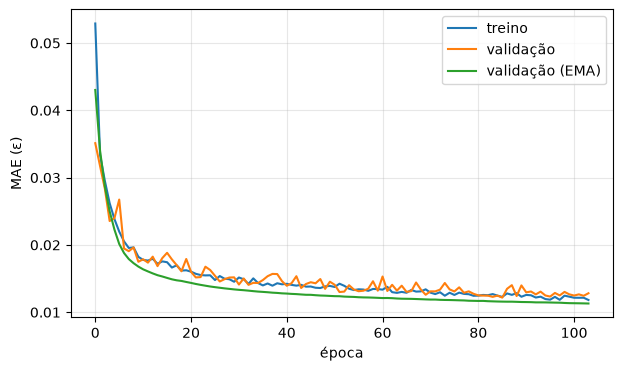

In [117]:
import matplotlib.pyplot as plt

plt.figure(figsize = (7, 4))
plt.plot(history['train'], label = 'treino')
plt.plot(history['val'], label = 'validação')
if 'val_ema' in history:
    plt.plot(history['val_ema'], label = 'validação (EMA)')
plt.xlabel('época')
plt.ylabel('MAE (ε)')
plt.legend()
plt.grid(alpha = 0.3)
plt.show()


In [118]:
idx = torch.arange(N_SAMPLES)
y_val, x_val = val_ds.y[idx].to(device), val_ds.x[idx].to(device)

torch.manual_seed(SEED)
x_pred = diffusion.generate(y_val, ddim_steps = VAL_DDIM_STEPS)

def snr_db(ref, est):
    return 10 * torch.log10((ref ** 2).sum(dim = (1, 2, 3)) / ((ref - est) ** 2).sum(dim = (1, 2, 3)))

snr = snr_db(x_val, x_pred).cpu()
mae = (x_val - x_pred).abs().mean(dim = (1, 2, 3)).cpu()
has_diff = x_val.abs().amax(dim = (1, 2, 3)).cpu() > 0     # alguns patches não têm difrações (label = 0)

print(f'MAE (todos os {N_SAMPLES} patches)               : {mae.mean():.4f}')
print(f'SNR ({has_diff.sum()} patches com difrações)          : {snr[has_diff].mean():.2f} dB (± {snr[has_diff].std():.2f})')
print(f'max|pred| nos patches sem difrações : {x_pred[~has_diff.to(device)].abs().max().item() if (~has_diff).any() else float("nan"):.4f}')


DDIM 100 passos: 100%|██████████| 100/100 [00:22<00:00,  4.39it/s]


MAE (todos os 16 patches)               : 0.0158
SNR (16 patches com difrações)          : 6.27 dB (± 7.68)
max|pred| nos patches sem difrações : nan


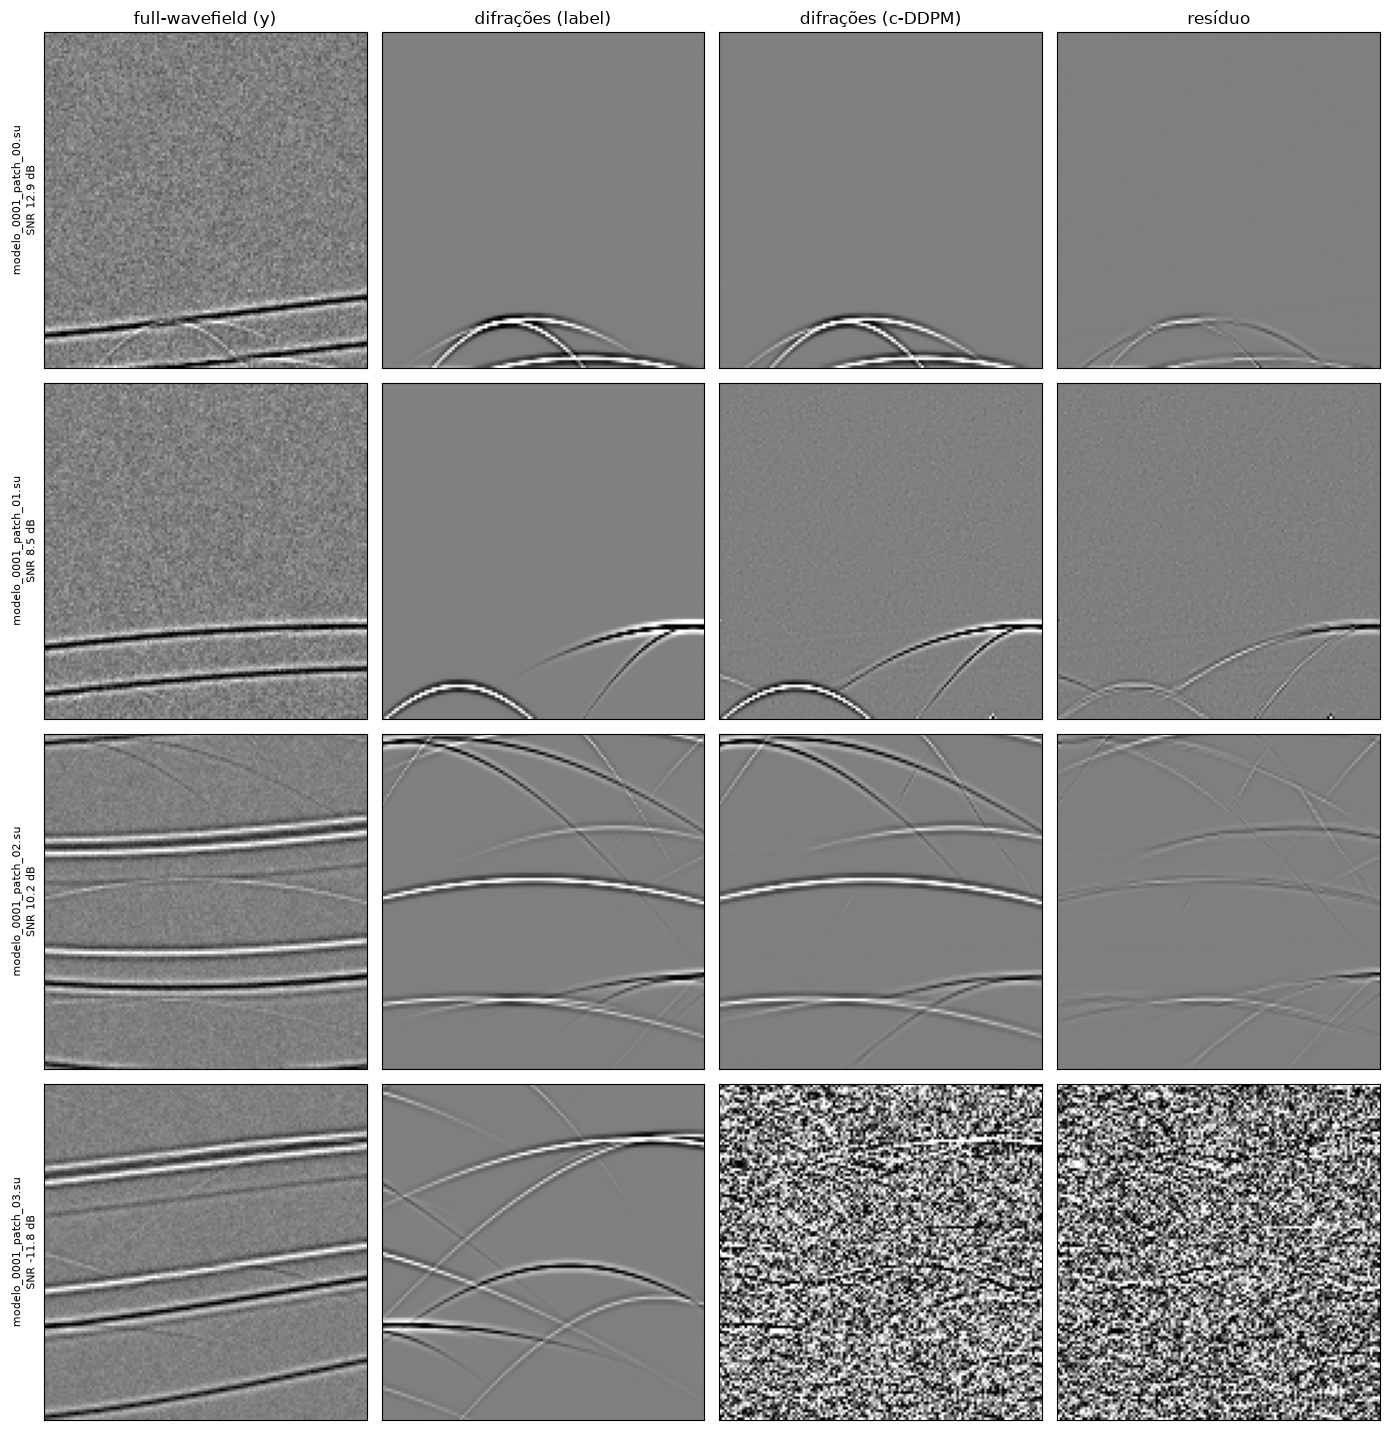

In [119]:
n_show = min(4, N_SAMPLES)
fig, axes = plt.subplots(n_show, 4, figsize = (14, 3.6 * n_show))
titles = ['full-wavefield (y)', 'difrações (label)', 'difrações (c-DDPM)', 'resíduo']

for row in range(n_show):
    y_i, x_i, p_i = (a[row, 0].cpu().numpy() for a in (y_val, x_val, x_pred))
    clip_y = np.percentile(np.abs(y_i), 99)
    clip_x = np.percentile(np.abs(x_i), 99) + 1e-8
    for col, (img, clip) in enumerate([(y_i, clip_y), (x_i, clip_x), (p_i, clip_x), (x_i - p_i, clip_x)]):
        ax = axes[row, col]
        ax.imshow(img, cmap = 'gray', aspect = 'auto', vmin = -clip, vmax = clip)
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(titles[col])
    axes[row, 0].set_ylabel(f'{val_ds.names[row]}\nSNR {snr[row]:.1f} dB', fontsize = 8)

plt.tight_layout()
plt.show()


# Teste

In [142]:
TEST_FILE = Path('/petrogeo/home/raphaelrds/Documentos/SISMICA/marine-geom-co100.su')   # dado marinho real, common offset 100 m
OUT_FILE = CKPT_DIR / f'{TEST_FILE.stem}_difracoes_cddpm.su'

PATCH = 128
STRIDE = 32              # 75% de sobreposição entre patches, como no artigo
TEST_BATCH = 16
TEST_DDIM_STEPS = 300    # None → Algoritmo 2 com T = 1000 passos (~15 min para 55 patches na T1000)
REMOVE_PATCH_MEAN = True # tira o nível DC de cada patch previsto antes de juntar
MERGE_WINDOW = 'hann'    # 'hann' → pesos suaves na sobreposição; None → média simples (artigo)


In [143]:
def read_su_header(path):
    raw = np.fromfile(path, dtype = np.uint8)
    ns = int(raw[114:116].view('<i2')[0])
    dt = int(raw[116:118].view('<i2')[0]) * 1e-6
    return ns, dt


def write_su(path_in, path_out, data):
    # copia os headers do arquivo original e troca as amostras
    raw = np.fromfile(path_in, dtype = np.uint8)
    ns, n_traces = data.shape
    traces = raw.reshape(n_traces, 240 + 4 * ns).copy()
    traces[:, 240:] = np.ascontiguousarray(data.T, dtype = '<f4').view(np.uint8).reshape(n_traces, 4 * ns)
    traces.tofile(path_out)


def pad_to_patches(d, patch = PATCH, stride = STRIDE):
    # zero padding no fim de cada eixo até caber um número inteiro de passos
    target = lambda n: patch + int(np.ceil(max(n - patch, 0) / stride)) * stride
    nt, nx = d.shape
    return np.pad(d, ((0, target(nt) - nt), (0, target(nx) - nx)))


def extract_patches(d, patch = PATCH, stride = STRIDE):
    H, W = d.shape
    pos = [(i, j) for i in range(0, H - patch + 1, stride) for j in range(0, W - patch + 1, stride)]
    return np.stack([d[i:i + patch, j:j + patch] for i, j in pos]), pos


def merge_window(patch = PATCH, kind = MERGE_WINDOW):
    if kind is None:
        return np.ones((patch, patch))
    w = np.hanning(patch + 2)[1:-1]          # sem zeros nas pontas: as bordas do dado continuam cobertas
    return np.outer(w, w)


def merge_patches(patches, pos, shape, patch = PATCH, window = None):
    # média ponderada das predições sobrepostas
    window = merge_window(patch) if window is None else window
    out, weight = np.zeros(shape), np.zeros(shape)
    for p, (i, j) in zip(patches, pos):
        out[i:i + patch, j:j + patch] += p * window
        weight[i:i + patch, j:j + patch] += window
    return out / np.maximum(weight, 1e-12)

y_real = read_su(TEST_FILE).astype(np.float64)
ns_real, dt_real = read_su_header(TEST_FILE)
nt, nx = y_real.shape

y_pad = pad_to_patches(y_real)
y_patches, positions = extract_patches(y_pad)

# reconstrução sem rede deve devolver o dado original
assert np.allclose(merge_patches(y_patches, positions, y_pad.shape)[:nt, :nx], y_real)

print(f'dado real   : {nt} amostras × {nx} traços (dt = {dt_real * 1e3:.0f} ms)')
print(f'com padding : {y_pad.shape[0]} × {y_pad.shape[1]}')
print(f'patches     : {len(y_patches)} de {PATCH}×{PATCH} (stride {STRIDE})')


dado real   : 426 amostras × 250 traços (dt = 4 ms)
com padding : 448 × 256
patches     : 55 de 128×128 (stride 32)


In [144]:
# mesma normalização do treino: cada patch dividido pelo seu max|y|
scales = np.abs(y_patches).max(axis = (1, 2), keepdims = True)
scales[scales == 0] = 1.
y_norm = torch.from_numpy(y_patches / scales).float().unsqueeze(1)

torch.manual_seed(SEED)
pred = []
for k in range(0, len(y_norm), TEST_BATCH):
    print(f'patches {k + 1}-{min(k + TEST_BATCH, len(y_norm))} de {len(y_norm)}')
    pred.append(diffusion.generate(y_norm[k:k + TEST_BATCH].to(device), ddim_steps = TEST_DDIM_STEPS).cpu())
pred = torch.cat(pred)[:, 0].numpy() * scales                       # predições brutas, uma por patch


patches 1-16 de 55


DDIM 300 passos: 100%|██████████| 300/300 [01:08<00:00,  4.40it/s]


patches 17-32 de 55


DDIM 300 passos: 100%|██████████| 300/300 [01:08<00:00,  4.35it/s]


patches 33-48 de 55


DDIM 300 passos: 100%|██████████| 300/300 [01:09<00:00,  4.32it/s]


patches 49-55 de 55


DDIM 300 passos: 100%|██████████| 300/300 [00:33<00:00,  8.91it/s]


In [145]:
pred_merge = pred - pred.mean(axis = (1, 2), keepdims = True) if REMOVE_PATCH_MEAN else pred

diff_real = merge_patches(pred_merge, positions, y_pad.shape)[:nt, :nx]   # remove o padding
refl_real = y_real - diff_real

write_su(TEST_FILE, OUT_FILE, diff_real)
print('salvo em', OUT_FILE)


salvo em /petrogeo/home/raphaelrds/Github/denoising-diffusion-pytorch/notebooks/checkpoints/marine-geom-co100_difracoes_cddpm.su


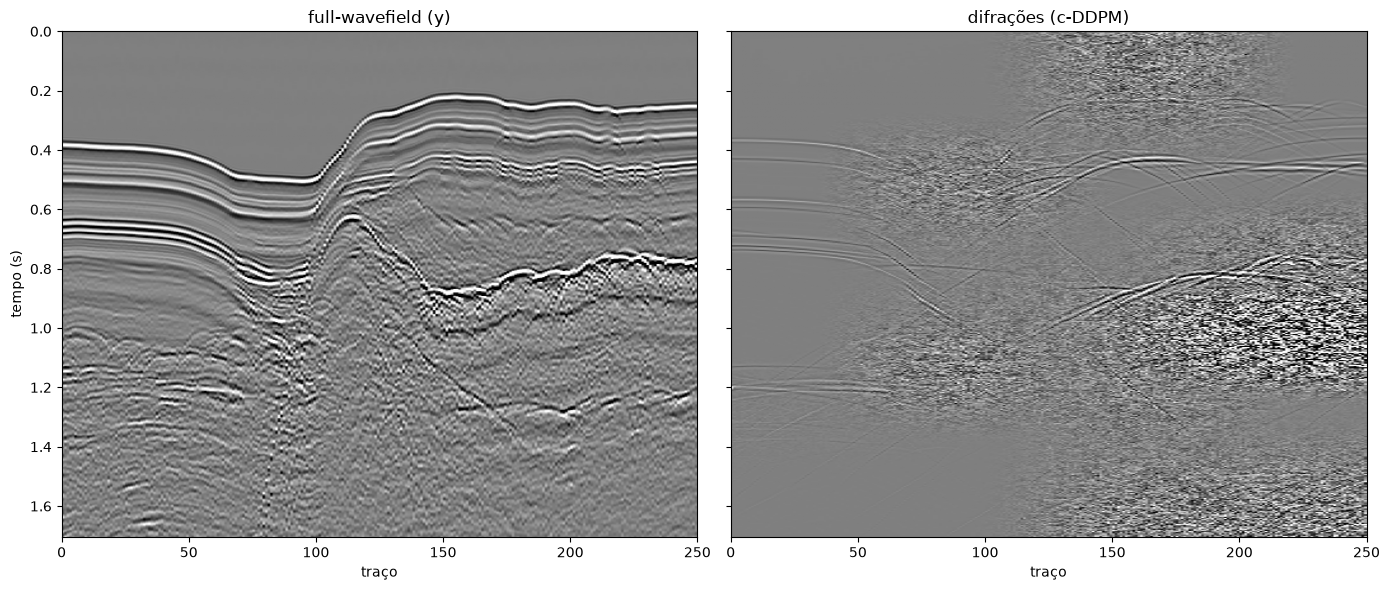

In [146]:
extent = [0, nx, nt * dt_real, 0]
clip = np.percentile(np.abs(y_real), 98)
clip_d = np.percentile(np.abs(diff_real), 98)

fig, axes = plt.subplots(1, 2, figsize = (14, 6), sharey = True)
for ax, img, c, title in zip(
    axes,
    (y_real, diff_real),
    (clip, clip_d),
    ('full-wavefield (y)', 'difrações (c-DDPM)'),
):
    ax.imshow(img, cmap = 'gray', aspect = 'auto', vmin = -c, vmax = c, extent = extent)
    ax.set_title(title)
    ax.set_xlabel('traço')
axes[0].set_ylabel('tempo (s)')
plt.tight_layout()
plt.show()
